In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset into Pandas DataFrame
df = pd.read_csv('/content/electricity_bill_dataset.csv')
df

,Fan,Refrigerator,AirConditioner,Television,Monitor,MotorPump,Month,City,Company,MonthlyHours,TariffRate,ElectricityBill
0,16,23.0,2.0,6.0,1.0,0,10,Hyderabad,Tata Power Company Ltd.,384,8.4,3225.6
1,19,22.0,2.0,3.0,1.0,0,5,Vadodara,NHPC,488,7.8,3806.4
2,7,20.0,2.0,6.0,7.0,0,7,Shimla,Jyoti Structure,416,7.7,3203.2
3,7,22.0,3.0,21.0,1.0,0,6,Mumbai,Power Grid Corp,475,9.2,4370.0
4,11,23.0,2.0,11.0,1.0,0,2,Mumbai,Ratnagiri Gas and Power Pvt. Ltd. (RGPPL),457,9.2,4204.4
...,...,...,...,...,...,...,...,...,...,...,...,...
45340,18,22.0,3.0,22.0,1.0,0,9,Ahmedabad,Maha Transco – Maharashtra State Electricity T...,764,7.9,6035.6
45341,23,23.0,2.0,6.0,12.0,0,2,New Delhi,Orient Green,572,8.5,4862.0
45342,22,22.0,2.0,20.0,1.0,0,1,New Delhi,GE T&D India Limited,609,8.5,5176.5
45343,8,21.0,2.0,22.0,7.0,0,12,Ratnagiri,TransRail Lighting,748,7.4,5535.2


In [ ]:
# Smooth noisy data using a moving average
window_size = 1000
df['ElectricityBill_MA'] = df['ElectricityBill'].rolling(window=window_size).mean()
df['MonthlyHours_MA'] = df['MonthlyHours'].rolling(window=window_size).mean()

In [ ]:
# Calculate slope (m) using 1st-degree polynomial fit y = mx + c
x = np.arange(len(df))

slope_bill, intercept_bill = np.polyfit(x, df['ElectricityBill'], 1)
slope_hours, intercept_hours = np.polyfit(x, df['MonthlyHours'], 1)

trend_bill = slope_bill * x + intercept_bill
trend_hours = slope_hours * x + intercept_hours

print(f"Electricity Bill Slope: {slope_bill:.6f} -> {'UPTREND' if slope_bill > 0 else 'DOWNTREND'}")
print(f"Monthly Hours Slope:    {slope_hours:.6f} -> {'UPTREND' if slope_hours > 0 else 'DOWNTREND'}")

Electricity Bill Slope: 0.000177 -> UPTREND
Monthly Hours Slope:    0.000026 -> UPTREND


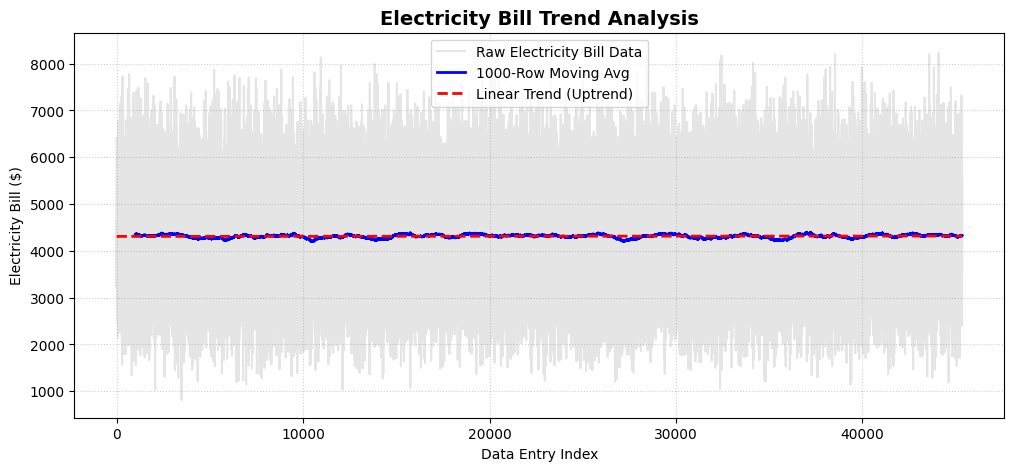

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(df.index, df['ElectricityBill'], alpha=0.2, color='gray', label='Raw Electricity Bill Data')
plt.plot(df.index, df['ElectricityBill_MA'], color='blue', linewidth=2, label=f'{window_size}-Row Moving Avg')
plt.plot(df.index, trend_bill, color='red', linestyle='--', linewidth=2,
         label=f"Linear Trend ({'Uptrend' if slope_bill > 0 else 'Downtrend'})")

plt.title('Electricity Bill Trend Analysis', fontsize=14, fontweight='bold')
plt.xlabel('Data Entry Index')
plt.ylabel('Electricity Bill ($)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

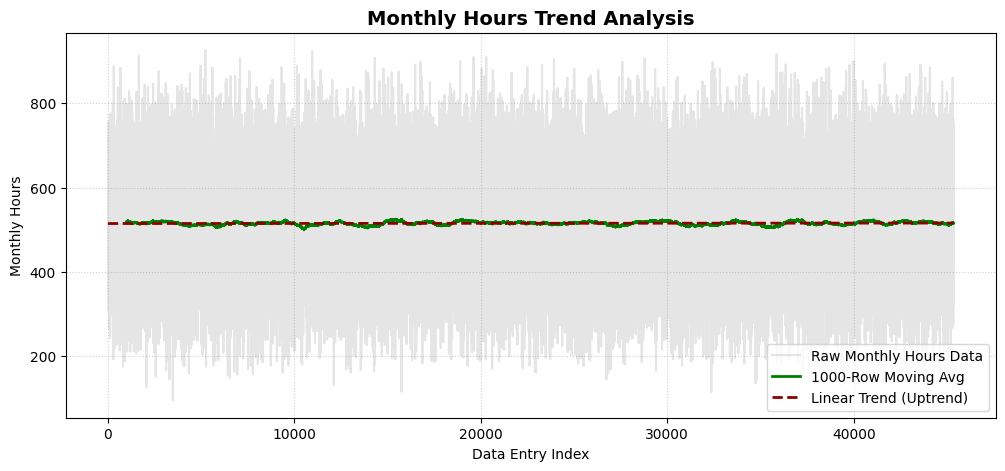

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(df.index, df['MonthlyHours'], alpha=0.2, color='gray', label='Raw Monthly Hours Data')
plt.plot(df.index, df['MonthlyHours_MA'], color='green', linewidth=2, label=f'{window_size}-Row Moving Avg')
plt.plot(df.index, trend_hours, color='darkred', linestyle='--', linewidth=2,
         label=f"Linear Trend ({'Uptrend' if slope_hours > 0 else 'Downtrend'})")

plt.title('Monthly Hours Trend Analysis', fontsize=14, fontweight='bold')
plt.xlabel('Data Entry Index')
plt.ylabel('Monthly Hours')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()